# 🎯 Notebook 1: Goal Classifier
**Objective:** User ke goal text se career predict karna.

**Pipeline:**
1. Baseline: TF-IDF + Logistic Regression
2. Advanced: Sentence Embeddings + Logistic Regression
3. Evaluation: Accuracy, F1, Confusion Matrix
4. Best model joblib se save karna

**Input:** `data/goal_texts.csv`  
**Output:** `ml/models/goal_classifier.joblib`, `ml/models/tfidf_vectorizer.joblib`

## 📦 0. Imports & Setup

In [ ]:
import pandas as pd
import numpy as np
import joblib
import json
import os
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

# Paths
DATA_DIR   = '../data'
MODEL_DIR  = 'models'
REPORT_DIR = 'reports'
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

print('Setup complete ✅')

Setup complete ✅


## 📂 1. Data Loading & EDA

In [ ]:
df = pd.read_csv(f'{DATA_DIR}/goal_texts.csv')
print(f'Total samples: {len(df)}')
print(f'Columns: {list(df.columns)}')
print()
print('Class distribution:')
print(df['career'].value_counts())
df.head(10)

Total samples: 98
Columns: ['text', 'career']

Class distribution:
career
Data Scientist          35
Web Developer           32
Full Stack Developer    31
Name: count, dtype: int64


,text,career
0,mujhe data science seekhna hai,Data Scientist
1,main data scientist banna chahta hoon,Data Scientist
2,mujhe machine learning mein career banana hai,Data Scientist
3,data analysis karna chahta hoon,Data Scientist
4,AI aur ML field mein jaana chahta hoon,Data Scientist
5,mujhe python aur data science dono seekhne hain,Data Scientist
6,data se insights nikalna mujhe pasand hai,Data Scientist
7,main statistician banna chahta hoon,Data Scientist
8,data driven decisions lena seekhna hai,Data Scientist
9,mujhe predictive models banana hai,Data Scientist


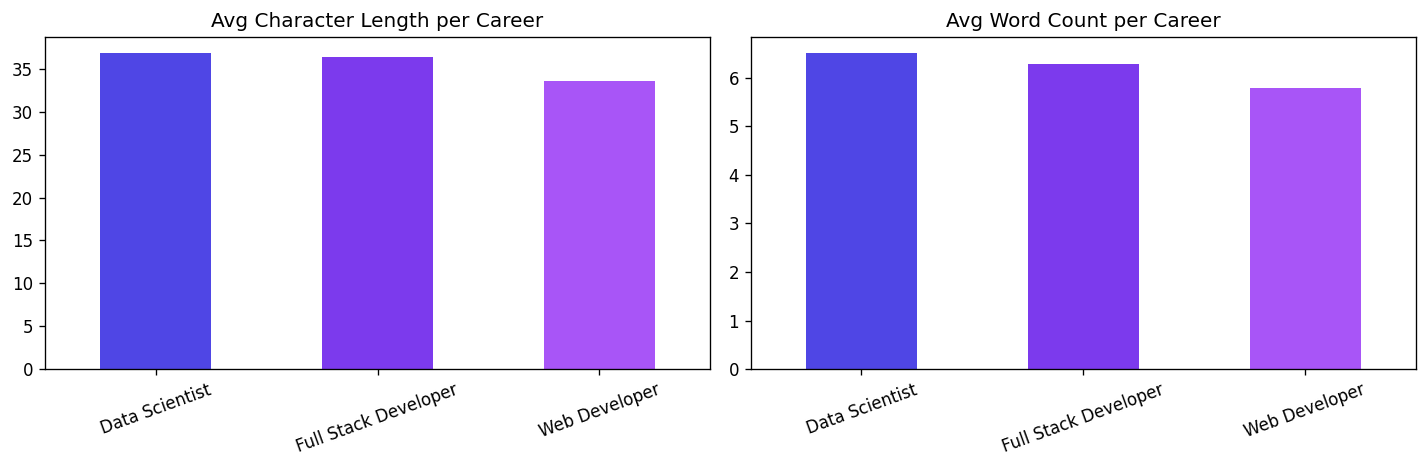

EDA plot saved ✅


In [ ]:
# Text length analysis
df['text_len'] = df['text'].str.len()
df['word_count'] = df['text'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in zip(axes, ['text_len', 'word_count'], ['Character Length', 'Word Count']):
    df.groupby('career')[col].mean().plot(kind='bar', ax=ax, color=['#4f46e5','#7c3aed','#a855f7'])
    ax.set_title(f'Avg {title} per Career')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig(f'{REPORT_DIR}/text_eda.png', bbox_inches='tight')
plt.show()
print('EDA plot saved ✅')

## ✂️ 2. Train / Test Split

In [ ]:
X = df['text'].values
y = df['career'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Train size : {len(X_train)}')
print(f'Test  size : {len(X_test)}')
print()
print('Train class counts:', dict(zip(*np.unique(y_train, return_counts=True))))
print('Test  class counts:', dict(zip(*np.unique(y_test,  return_counts=True))))

TypeError: only integer scalar arrays can be converted to a scalar index

## 🔢 3. Baseline — TF-IDF + Logistic Regression

In [ ]:
# Build pipeline
tfidf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=5000,
        sublinear_tf=True,
        min_df=1
    )),
    ('clf', LogisticRegression(max_iter=500, C=1.0, random_state=42))
])

# Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(tfidf_pipeline, X_train, y_train, cv=cv, scoring='accuracy')
print(f'TF-IDF CV Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')

# Train
tfidf_pipeline.fit(X_train, y_train)

# Evaluate on test
y_pred_tfidf = tfidf_pipeline.predict(X_test)
acc_tfidf  = accuracy_score(y_test, y_pred_tfidf)
f1_tfidf   = f1_score(y_test, y_pred_tfidf, average='weighted')

print(f'\n[TF-IDF LR] Test Accuracy : {acc_tfidf:.4f}')
print(f'[TF-IDF LR] Test F1 (weighted): {f1_tfidf:.4f}')
print()
print(classification_report(y_test, y_pred_tfidf))

NameError: name 'X_train' is not defined

In [ ]:
# Confusion matrix — TF-IDF
fig, ax = plt.subplots(figsize=(7, 5))
cm = confusion_matrix(y_test, y_pred_tfidf, labels=tfidf_pipeline.classes_)
disp = ConfusionMatrixDisplay(cm, display_labels=tfidf_pipeline.classes_)
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Confusion Matrix — TF-IDF + LR', fontsize=13)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(f'{REPORT_DIR}/cm_tfidf.png', bbox_inches='tight')
plt.show()

## 🤖 4. Advanced — Sentence Embeddings + Logistic Regression

In [ ]:
from sentence_transformers import SentenceTransformer

print('Loading embedding model... (first time may download ~90MB)')
embedder = SentenceTransformer('all-MiniLM-L6-v2')
print('Model loaded ✅')

# Encode all texts
print('Encoding texts...')
X_train_emb = embedder.encode(X_train.tolist(), show_progress_bar=True, batch_size=32)
X_test_emb  = embedder.encode(X_test.tolist(),  show_progress_bar=True, batch_size=32)
print(f'Embedding shape: {X_train_emb.shape}')

Loading embedding model... (first time may download ~90MB)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model loaded ✅
Encoding texts...


NameError: name 'X_train' is not defined

In [ ]:
# Train embedding classifier
emb_clf = LogisticRegression(max_iter=500, C=5.0, random_state=42)

# Cross-validation on embeddings
cv_emb = cross_val_score(emb_clf, X_train_emb, y_train, cv=cv, scoring='accuracy')
print(f'Embedding CV Accuracy: {cv_emb.mean():.4f} ± {cv_emb.std():.4f}')

emb_clf.fit(X_train_emb, y_train)
y_pred_emb = emb_clf.predict(X_test_emb)

acc_emb = accuracy_score(y_test, y_pred_emb)
f1_emb  = f1_score(y_test, y_pred_emb, average='weighted')

print(f'\n[Embedding LR] Test Accuracy : {acc_emb:.4f}')
print(f'[Embedding LR] Test F1 (weighted): {f1_emb:.4f}')
print()
print(classification_report(y_test, y_pred_emb))

In [ ]:
# Confusion matrix — Embeddings
fig, ax = plt.subplots(figsize=(7, 5))
cm2 = confusion_matrix(y_test, y_pred_emb, labels=emb_clf.classes_)
ConfusionMatrixDisplay(cm2, display_labels=emb_clf.classes_).plot(ax=ax, colorbar=False, cmap='Purples')
ax.set_title('Confusion Matrix — Sentence Embedding + LR', fontsize=13)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(f'{REPORT_DIR}/cm_embedding.png', bbox_inches='tight')
plt.show()

## 📊 5. Model Comparison

In [ ]:
results = {
    'TF-IDF + LR': {'accuracy': acc_tfidf, 'f1_weighted': f1_tfidf, 'cv_mean': cv_scores.mean(), 'cv_std': cv_scores.std()},
    'Embedding + LR': {'accuracy': acc_emb, 'f1_weighted': f1_emb, 'cv_mean': cv_emb.mean(), 'cv_std': cv_emb.std()}
}

results_df = pd.DataFrame(results).T.round(4)
print('=== Model Comparison ===')
print(results_df.to_string())

# Bar chart
fig, ax = plt.subplots(figsize=(8, 4))
metrics = ['accuracy', 'f1_weighted']
x = np.arange(len(metrics))
width = 0.35
bars1 = ax.bar(x - width/2, [results['TF-IDF + LR'][m] for m in metrics], width, label='TF-IDF + LR', color='#4f46e5')
bars2 = ax.bar(x + width/2, [results['Embedding + LR'][m] for m in metrics], width, label='Embedding + LR', color='#a855f7')
ax.set_xticks(x)
ax.set_xticklabels(['Accuracy', 'F1 (Weighted)'])
ax.set_ylim(0, 1.1)
ax.set_title('Goal Classifier — Model Comparison', fontsize=13)
ax.legend()
for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(f'{REPORT_DIR}/model_comparison.png', bbox_inches='tight')
plt.show()

# Save results JSON
with open(f'{REPORT_DIR}/goal_classifier_results.json', 'w') as f:
    json.dump(results, f, indent=2)
print('Results saved ✅')

## 💾 6. Save Best Model

In [ ]:
# Choose best model based on F1
best_name = max(results, key=lambda k: results[k]['f1_weighted'])
print(f'Best model: {best_name}')

if best_name == 'TF-IDF + LR':
    joblib.dump(tfidf_pipeline, f'{MODEL_DIR}/goal_classifier.joblib')
    print(f'Saved: {MODEL_DIR}/goal_classifier.joblib (TF-IDF Pipeline)')
else:
    joblib.dump(emb_clf, f'{MODEL_DIR}/goal_classifier_emb.joblib')
    joblib.dump(embedder, f'{MODEL_DIR}/sentence_embedder.joblib')
    # Also save tfidf as fallback
    joblib.dump(tfidf_pipeline, f'{MODEL_DIR}/goal_classifier_tfidf_fallback.joblib')
    print(f'Saved: {MODEL_DIR}/goal_classifier_emb.joblib')
    print(f'Saved: {MODEL_DIR}/sentence_embedder.joblib')

# Always save the TF-IDF vectorizer separately too (for the API)
joblib.dump(tfidf_pipeline.named_steps['tfidf'], f'{MODEL_DIR}/tfidf_vectorizer.joblib')
joblib.dump(tfidf_pipeline.named_steps['clf'],  f'{MODEL_DIR}/goal_clf_lr.joblib')
print('TF-IDF components saved separately ✅')

## 🔍 7. Quick Inference Test

In [ ]:
test_sentences = [
    'mujhe data science seekhna hai',
    'I want to build websites with React',
    'main MERN stack developer banna chahta hoon',
    'machine learning mein career banana hai',
    'mujhe frontend aur backend dono seekhne hain',
    'CSS aur HTML se website banana chahta hoon',
    'deep learning aur NLP mein interest hai',
    'complete web application banana chahta hoon',
]

print('=== Inference Test (TF-IDF Pipeline) ===')
preds = tfidf_pipeline.predict(test_sentences)
probas = tfidf_pipeline.predict_proba(test_sentences)
classes = tfidf_pipeline.classes_

for sent, pred, prob in zip(test_sentences, preds, probas):
    conf = prob.max()
    print(f'  Input  : "{sent}"')
    print(f'  Predict: {pred}  (confidence: {conf:.2%})')
    print(f'  Probs  : { {c: f"{p:.2%}" for c, p in zip(classes, prob)} }')
    print()